# 01 · Data, model and data audit

**Question this notebook answers:** what exactly is the model we are explaining, how
good is it, and is the data clean enough that its explanations can be trusted?

The task: given only the **title** of a computer-science paper, recommend one of five
venues — INFOCOM (networking), ISCAS (circuits & systems), SIGGRAPH (graphics),
VLDB (databases) or WWW (the Web). The model is deliberately simple and transparent:
spaCy lemmatisation → TF-IDF (uni- and bigrams) → one-vs-rest logistic regression.

Everything is loaded through `tcner_xai.model.load_bundle()`, so all notebooks explain
the *same* fitted model with the *same* preprocessing.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from sklearn.metrics import classification_report, confusion_matrix, f1_score

from tcner_xai import plotting
from tcner_xai.config import CLASSES, RESULTS_DIR, SEED
from tcner_xai.data import SpacyPreprocessor, audit, is_boilerplate, normalise_title
from tcner_xai.model import VenueClassifier, load_bundle

plotting.set_style()
pd.set_option("display.max_colwidth", 90)
B = load_bundle()
model, train, test = B.model, B.train, B.test

train=21,497 test=3,373 features=5,000 test accuracy=0.8615


## 1. The data and a large train/test label shift

The training and test sets do **not** share the same venue mix: ISCAS makes up about a
third of the training titles but almost two thirds of the test titles. This matters
later for calibration (notebook 05): a model's confidence is learned under the
training priors.

,train (raw),train (deduplicated),test
label,,,
INFOCOM,4481,4423,502
ISCAS,7514,7514,2043
SIGGRAPH,2678,2632,186
VLDB,3678,3639,219
WWW,3292,3289,423


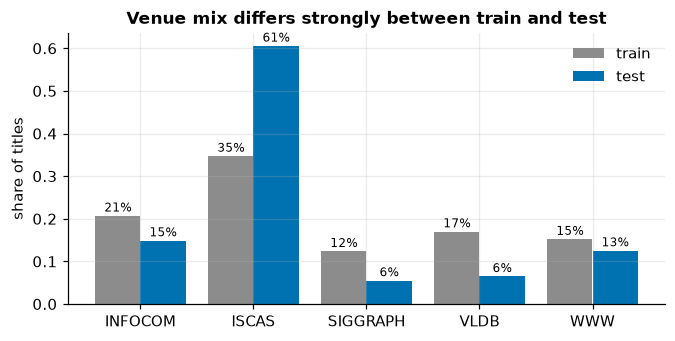

In [2]:
dist = pd.DataFrame({
    "train": B.train_raw["label"].value_counts(normalize=True),
    "test": test["label"].value_counts(normalize=True),
}).loc[CLASSES]
counts = pd.DataFrame({
    "train (raw)": B.train_raw["label"].value_counts(),
    "train (deduplicated)": train["label"].value_counts(),
    "test": test["label"].value_counts(),
}).loc[CLASSES]
display(counts)

fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(CLASSES))
ax.bar(x - 0.2, dist["train"], 0.4, label="train", color="#8C8C8C")
ax.bar(x + 0.2, dist["test"], 0.4, label="test", color="#0072B2")
ax.set_xticks(x, CLASSES)
ax.set_ylabel("share of titles")
ax.set_title("Venue mix differs strongly between train and test")
ax.legend()
for i, c in enumerate(CLASSES):
    ax.text(i + 0.2, dist.loc[c, "test"] + 0.01, f"{dist.loc[c, 'test']:.0%}", ha="center", fontsize=8)
    ax.text(i - 0.2, dist.loc[c, "train"] + 0.01, f"{dist.loc[c, 'train']:.0%}", ha="center", fontsize=8)
plotting.save(fig, "01_class_distribution")
plt.show()

## 2. Model performance

Same configuration as the original submission (TF-IDF: 5,000 uni/bigrams, `min_df=3`,
`max_df=0.85`; liblinear logistic regression, one-vs-rest). Because the app would show a
*ranked list* of venues, we also report top-2 and top-3 accuracy.

In [3]:
proba_test = model.clf.predict_proba(B.X_test)
y_pred = model.classes_[proba_test.argmax(1)]
y_idx = np.array([model.class_index(c) for c in B.y_test])

report = classification_report(B.y_test, y_pred, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.round(3)
display(report_df)

ranked = np.argsort(-proba_test, axis=1)
topk = {f"top-{k} accuracy": float(np.mean([y in r[:k] for y, r in zip(y_idx, ranked)])) for k in (1, 2, 3)}
summary = pd.Series({
    **topk,
    "macro F1": f1_score(B.y_test, y_pred, average="macro"),
    "weighted F1": f1_score(B.y_test, y_pred, average="weighted"),
}).round(4)
display(summary.to_frame("value"))
report_df.to_csv(RESULTS_DIR / "model_classification_report.csv")
summary.to_csv(RESULTS_DIR / "model_summary.csv", header=["value"])

,precision,recall,f1-score,support
INFOCOM,0.761,0.755,0.758,502.000
ISCAS,0.937,0.939,0.938,2043.000
SIGGRAPH,0.760,0.747,0.753,186.000
VLDB,0.602,0.767,0.675,219.000
WWW,0.823,0.714,0.765,423.000
accuracy,0.862,0.862,0.862,0.862
macro avg,0.777,0.784,0.778,3373.000
weighted avg,0.865,0.862,0.862,3373.000


,value
top-1 accuracy,0.8615
top-2 accuracy,0.9558
top-3 accuracy,0.9819
macro F1,0.7778
weighted F1,0.8623


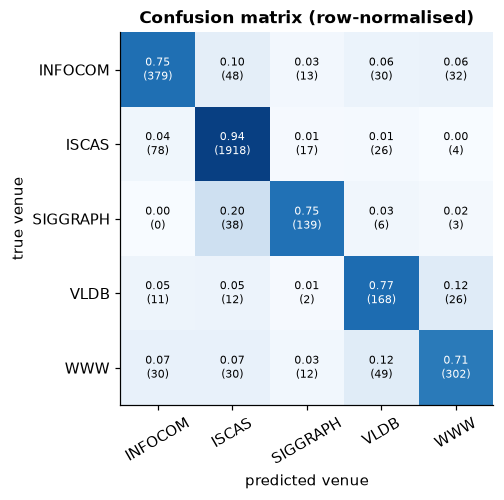

In [4]:
cm = confusion_matrix(B.y_test, y_pred, labels=CLASSES)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=7.5,
                color="white" if cm_norm[i, j] > 0.6 else "black")
ax.set_xticks(range(5), CLASSES, rotation=30)
ax.set_yticks(range(5), CLASSES)
ax.set_xlabel("predicted venue")
ax.set_ylabel("true venue")
ax.set_title("Confusion matrix (row-normalised)")
ax.grid(False)
plotting.save(fig, "01_confusion_matrix")
plt.show()

## 3. A bug in the original explanation pipeline

In the original notebook, LIME and Anchors called `model.predict(vectorizer.transform(title))`
on the **raw** title. The vectoriser was fitted on *lemmatised, stop-word-filtered* text,
so the explainers queried a slightly different function than the one that was
evaluated (e.g. `systems` vs `system`, `networks` vs `network`). How often does that
actually change the prediction?

In [5]:
raw_path = model.clf.predict_proba(model.vectorizer.transform(test["title"]))
same_label = raw_path.argmax(1) == proba_test.argmax(1)
bug = pd.Series({
    "test titles whose predicted venue changes": int((~same_label).sum()),
    "share of test titles": round(float((~same_label).mean()), 4),
    "mean |change| in P(predicted venue)": round(float(np.abs(
        raw_path[np.arange(len(test)), proba_test.argmax(1)] - proba_test.max(1)).mean()), 4),
    "accuracy, raw-title path": round(float((model.classes_[raw_path.argmax(1)] == B.y_test).mean()), 4),
    "accuracy, correct path": round(float((y_pred == B.y_test).mean()), 4),
})
display(bug.to_frame("value"))
bug.to_csv(RESULTS_DIR / "original_pipeline_bug.csv", header=["value"])

examples = test.loc[~same_label, ["title", "label"]].assign(
    pred_correct_path=y_pred[~same_label],
    pred_raw_path=model.classes_[raw_path.argmax(1)][~same_label],
).head(8)
display(examples)

,value
test titles whose predicted venue changes,283.0000
share of test titles,0.0839
mean |change| in P(predicted venue),0.0778
"accuracy, raw-title path",0.8280
"accuracy, correct path",0.8615


,title,label,pred_correct_path,pred_raw_path
1,High-Throughput Data Compressor Designs Using Content Addressable Memory.,ISCAS,ISCAS,VLDB
13,Computer Formulation of Averaged Models for Periodically-Switched Networks.,ISCAS,INFOCOM,SIGGRAPH
21,Minimum-cost augmentation to 3-edge-connect all specified vertices in a graph.,ISCAS,ISCAS,INFOCOM
28,Minimum Density Interconneciton Trees.,ISCAS,VLDB,ISCAS
30,Bounds for Distributed Parameter Trees.,ISCAS,VLDB,ISCAS
31,YouTube monetization: creating user-centric experiences using large scale data.,WWW,WWW,VLDB
41,Novel applications of row-semi-indefinite networks.,ISCAS,INFOCOM,ISCAS
48,Analysis and Experiments for a Parallel Solution to the All Pairs Shortest Path Problem.,ISCAS,VLDB,INFOCOM


All explainers in this repository go through `VenueClassifier.proba_clean` (cleaned text)
or `proba_raw` (raw text + the same spaCy pipeline), so this cannot happen again.

We also check that the faster preprocessor (parser and NER disabled) produces exactly
the same cleaned text as the original `nlp(text.lower())`:

In [6]:
full_nlp = spacy.load("en_core_web_sm")
sample = test["title"].sample(500, random_state=SEED)
original_rule = [SpacyPreprocessor._clean_doc(full_nlp(t.lower())) for t in sample]
assert original_rule == B.pre(list(sample)), "fast preprocessing differs from the original"
print("Fast preprocessor identical to the original pipeline on 500 titles ✓")

Fast preprocessor identical to the original pipeline on 500 titles ✓


## 4. Data audit: duplicates, leakage and boilerplate titles

Explanations are only as trustworthy as the data. The audit looks for duplicate titles,
titles that appear in *both* train and test (leakage), titles with conflicting labels,
and **boilerplate** entries such as *Front Matter* or *Keynote* that describe a
proceedings artefact, not research. Boilerplate titles carry no topical signal, so if
the model predicts them confidently it must be using a shortcut.

In [7]:
report_audit, tables = audit(B.train_raw, test)
audit_df = report_audit.as_frame()
display(audit_df)
audit_df.to_csv(RESULTS_DIR / "data_audit.csv")

,value
check,
n_train,21643
n_test,3373
train_dup_titles,190
train_conflicting_titles,2
test_dup_titles,13
cross_split_overlap,12
cross_split_label_mismatch,0
train_boilerplate,47
test_boilerplate,12


In [8]:
print("Most frequent training titles:")
display(tables["most_common_train_titles"].head(12))
print("Boilerplate titles in the training set, by venue:")
display(tables["train_boilerplate_by_label"].head(15))

Most frequent training titles:


,count
norm,
front matter,17
statement for the session on impact of new technologies,5
letter from the the associate editors,4
letter from the the associate editor,4
a colloidal display membrane screen that combines transparency brdf and 3d volume,3
processing a learning environment for creating interactive web graphics,3
comments on the paper data base design in theory and practice by bo sundgren,3
reviewers list,3
troubleshooting slow webpage downloads,2


Boilerplate titles in the training set, by venue:


,norm,label,count
2,front matter,VLDB,17
8,letter from the the associate editor,VLDB,4
9,letter from the the associate editors,VLDB,4
18,reviewers list,INFOCOM,3
4,letter from the editor in chief,VLDB,2
7,letter from the research track co chair,VLDB,2
12,letter from the vldb 2011 research track co chair,VLDB,2
0,author index,VLDB,1
13,letter from the vldb proceedings chair,VLDB,1
17,message from the vldb 2012 general program chair,VLDB,1


In [9]:
print("Train/test overlap (same normalised title in both splits):")
display(tables["cross_split_overlap"].head(10))
print("Titles with conflicting venue labels in train:")
display(tables["conflicting_titles"].head(10))
print("HTML markup leaks into the model's tokens (e.g. 'elysium</i'):")
display(tables["html_markup_examples"].head(6))

Train/test overlap (same normalised title in both splits):


,title,label
569,Front Matter.,VLDB
841,Front Matter.,VLDB
843,Front Matter.,VLDB
1043,Front Matter.,VLDB
1683,Front Matter.,VLDB
1750,Front Matter.,VLDB
1921,Front Matter.,VLDB
2122,Front Matter.,VLDB
2241,Front Matter.,VLDB
2557,Front Matter.,VLDB


Titles with conflicting venue labels in train:


,title,label
5799,Crawling the Hidden Web.,WWW
8839,Crawling the Hidden Web.,VLDB
14178,Exploiting Content Redundancy for Web Information Extraction.,VLDB
15589,Exploiting content redundancy for web information extraction.,WWW


HTML markup leaks into the model's tokens (e.g. 'elysium</i'):


,title,clean,label
310,A 10GS/s 2V<sub>pp</sub> emitter follower only track and hold amplifier in SiGe BiCMOS...,10gs sub pp</sub emitter follower track hold amplifier sige bicmos technology,ISCAS
489,An interface for the I<sup>2</sup>C protocol in the WaferBoard&#8482;.,interface sup>2</sup protocol waferboard&#8482,ISCAS
898,<i>Bellows</i>: bringing digital animation into the physical world.,bellows</i bring digital animation physical world,SIGGRAPH
913,124dB.Hz<sup>2/3</sup> Dynamic range transimpedance amplifier for electronic-photonic ...,124db.hz sup>2/3</sup dynamic range transimpedance amplifier electronic photonic chann...,ISCAS
1075,GPS comics: <i>seeing thru walls</i>.,gps comic_strip see walls</i,SIGGRAPH
1093,P<sup>3</sup>N: profiling the potential of a peer-based data management system.,sup>3</sup profile potential peer base data management system,VLDB


### How does the model treat boilerplate test titles?

In [10]:
bp_mask = test["title"].map(is_boilerplate).values
bp = test.loc[bp_mask, ["title", "label"]].assign(
    predicted=y_pred[bp_mask], confidence=proba_test.max(1)[bp_mask].round(3))
display(bp)
print(f"Accuracy on boilerplate test titles: {(bp['label'] == bp['predicted']).mean():.2f} "
      f"(n={len(bp)}), mean confidence {bp['confidence'].mean():.2f}")

,title,label,predicted,confidence
569,Front Matter.,VLDB,VLDB,0.437
841,Front Matter.,VLDB,VLDB,0.437
843,Front Matter.,VLDB,VLDB,0.437
1043,Front Matter.,VLDB,VLDB,0.437
1683,Front Matter.,VLDB,VLDB,0.437
1750,Front Matter.,VLDB,VLDB,0.437
1921,Front Matter.,VLDB,VLDB,0.437
2122,Front Matter.,VLDB,VLDB,0.437
2241,Front Matter.,VLDB,VLDB,0.437
2557,Front Matter.,VLDB,VLDB,0.437


Accuracy on boilerplate test titles: 1.00 (n=12), mean confidence 0.44


### Does cleaning the data change the model?

We retrain on the training set **without** boilerplate titles and evaluate both models
on a *clean* test set (no boilerplate, no titles seen in training). The global
explanations in notebook 04 show where the shortcut surfaces (`matter` is among the 15
most important terms).

In [11]:
train_norm = set(B.train_raw["title"].map(normalise_title))
clean_test = (~bp_mask) & (~test["title"].map(normalise_title).isin(train_norm).values)
train_clean = train[~train["title"].map(is_boilerplate)]
model_clean = VenueClassifier().fit(train_clean["clean"], train_clean["label"])

rows = []
for name, m, tr in [("original model", model, train), ("retrained without boilerplate", model_clean, train_clean)]:
    for split, mask in [("full test", np.ones(len(test), bool)), ("clean test", clean_test)]:
        pred = m.predict_clean(test.loc[mask, "clean"])
        rows.append({"model": name, "train size": len(tr), "evaluated on": split, "n": int(mask.sum()),
                     "accuracy": (pred == B.y_test[mask]).mean(),
                     "macro F1": f1_score(B.y_test[mask], pred, average="macro")})
clean_df = pd.DataFrame(rows).round(4)
display(clean_df)
clean_df.to_csv(RESULTS_DIR / "clean_retrain.csv", index=False)

,model,train size,evaluated on,n,accuracy,macro F1
0,original model,21497,full test,3373,0.8615,0.7778
1,original model,21497,clean test,3361,0.8611,0.7745
2,retrained without boilerplate,21477,full test,3373,0.8615,0.7771
3,retrained without boilerplate,21477,clean test,3361,0.8611,0.7737


## Take-aways

* The classifier reproduces the original result (86.2% accuracy, macro F1 0.78); as a
  ranked recommender it is stronger — the right venue is in the top 2 for 95.6% of titles.
  Most errors are between topically overlapping venues (VLDB ↔ WWW, 12% each way) or
  go towards the dominant class ISCAS (20% of SIGGRAPH titles, 10% of INFOCOM titles).
* **The original LIME/Anchors code explained a different model.** Feeding raw titles to
  the vectoriser changes the predicted venue for 283 test titles (8.4%) and lowers
  accuracy to 82.8%. Every explainer in this repository now goes through one prediction
  function with the same preprocessing.
* The test set has a **very different venue mix** than the training set (ISCAS 35% → 61%).
* **Shortcut:** all 12 *Front Matter* test titles are “correctly” assigned to VLDB — only
  because the 17 *Front Matter* training titles were VLDB. Removing boilerplate barely
  changes overall accuracy (it is a small fraction of the data), but it is a textbook
  shortcut (Geirhos et al., 2020) that inflates accuracy and shows up in the global
  explanations.
* Smaller data issues: 2 titles with conflicting labels; the only test titles also seen
  in training are the 12 *Front Matter* entries; HTML markup (`<i>…</i>`) in 121 training
  and 24 test titles leaks into tokens such as `elysium</i`.